<a href="https://colab.research.google.com/github/AK888-hp/ML-II_Lab/blob/main/candidate_elim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Example: ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same'] +
S = ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']
G = [['?', '?', '?', '?', '?', '?']]

Example: ['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same'] +
S = ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
G = [['?', '?', '?', '?', '?', '?']]

Example: ['Rainy', 'Cold', 'High', 'Strong', 'Warm', 'Change'] -
S = ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
G = [['?', '?', '?', '?', 'Warm', '?'], ['?', '?', '?', 'Strong', '?', '?'], ['Sunny', '?', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', 'Same'], ['?', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?']]

Example: ['Sunny', 'Warm', 'High', 'Strong', 'Cool', 'Change'] +
S = ['Sunny', 'Warm', '?', 'Strong', '?', '?']
G = [['?', '?', '?', '?', '?', '?'], ['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?'], ['?', '?', '?', 'Strong', '?', '?']]

Final Most Specific Hypothesis:
['Sunny', 'Warm', '?', 'Strong', '?', '?']

Final Most Genera

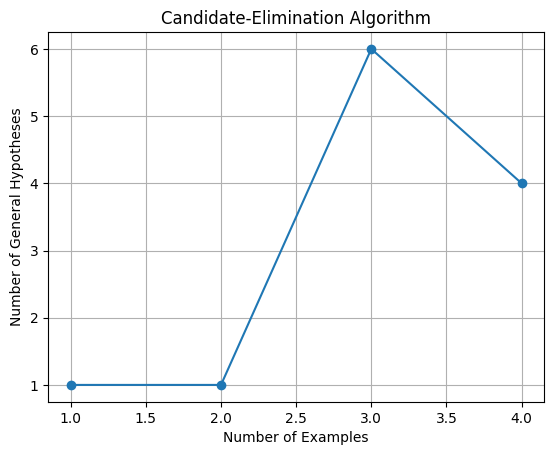

In [ ]:
import matplotlib.pyplot as plt

data = [
    (['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same'], '+'),
    (['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same'], '+'),
    (['Rainy', 'Cold', 'High', 'Strong', 'Warm', 'Change'], '-'),
    (['Sunny', 'Warm', 'High', 'Strong', 'Cool', 'Change'], '+')
]

# Initial hypotheses
S = ['0', '0', '0', '0', '0', '0']
G = [['?', '?', '?', '?', '?', '?']]

version_sizes = []


def covers(h, x):
    for a, b in zip(h, x):
        if a != '?' and a != b:
            return False
    return True


for example, label in data:

    if label == '+':
        # Generalize S
        for i in range(len(S)):
            if S[i] == '0':
                S[i] = example[i]
            elif S[i] != example[i]:
                S[i] = '?'

        # Remove G hypotheses that don't cover positive example
        G = [g for g in G if covers(g, example)]

    else:
        # Specialize G for negative example
        new_G = []

        for g in G:
            if covers(g, example):
                for i in range(len(g)):
                    if g[i] == '?':
                        h = g.copy()
                        h[i] = S[i]

                        if h[i] != '0':
                            new_G.append(h)
            else:
                new_G.append(g)

        G = new_G

    # Remove duplicates
    G = [list(x) for x in set(tuple(x) for x in G)]

    # Display
    print("Example:", example, label)
    print("S =", S)
    print("G =", G)
    print()

    version_sizes.append(len(G))


# Final results
print("Final Most Specific Hypothesis:")
print(S)

print("\nFinal Most General Hypotheses:")
for g in G:
    print(g)

print("\nVersion Space Size:")
print(version_sizes)


# -------------------------------
# Matplotlib graph
# -------------------------------

plt.plot(
    range(1, len(data) + 1),
    version_sizes,
    marker='o'
)

plt.xlabel("Number of Examples")
plt.ylabel("Number of General Hypotheses")
plt.title("Candidate-Elimination Algorithm")
plt.grid(True)

plt.show()
